In [1]:
print("hello")

hello


In [15]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from typing import Literal

In [16]:
class TicketState(TypedDict):
    ticket: str
    priority: str
    reply: str


In [17]:
URGENT_WORDS = ["down", "outage", "not working", "urgent"]

def check_priority(state: TicketState):
    text = state["ticket"].lower()
    is_urgent = any(word in text for word in URGENT_WORDS)
    return {"priority": "urgent" if is_urgent else "normal"}

def page_on_call(state: TicketState):
    print("Paging the on-call engineer...")
    return {"reply": "We are on it. An engineer has been alerted."}

def add_to_queue(state: TicketState):
    print("Adding ticket to the normal queue...")
    return {"reply": "Thanks! Our team will get back to you within 24 hours."}

In [18]:
def route_by_priority(state: TicketState) -> Literal["page_on_call", "add_to_queue"]:
    if state["priority"] == "urgent":
        return "page_on_call"
    return "add_to_queue"
    

In [19]:
# Building a graph
builder = StateGraph(TicketState)

In [20]:
# Nodes
builder.add_node("check_priority", check_priority)
builder.add_node("page_on_call", page_on_call)
builder.add_node("add_to_queue", add_to_queue)


In [21]:
# Edges
builder.add_edge(START, "check_priority")
builder.add_conditional_edges("check_priority", route_by_priority)
# builder.add_conditional_edges(
#     "check_priority", 
#     route_by_priority, 
#     {
#         "page_on_call": "page_on_call", 
#         "add_to_queue": "add_to_queue"
#     })
builder.add_edge("page_on_call", END)
builder.add_edge("add_to_queue", END)

In [22]:
graph = builder.compile()

In [23]:
print(graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	check_priority(check_priority)
	page_on_call(page_on_call)
	add_to_queue(add_to_queue)
	__end__([<p>__end__</p>]):::last
	__start__ --> check_priority;
	check_priority -.-> add_to_queue;
	check_priority -.-> page_on_call;
	add_to_queue --> __end__;
	page_on_call --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



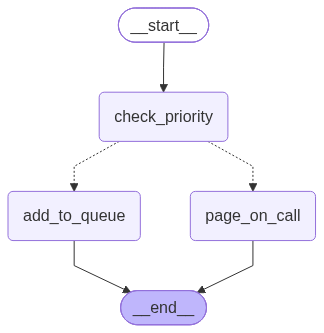

In [24]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [25]:
result = graph.invoke({"ticket": "Our website is down since morning!"})

Paging the on-call engineer...


In [26]:
result = graph.invoke({"ticket": "How do I change my billing address?"})

Adding ticket to the normal queue...
